# MCTP demo: token impact under pruning

Monte Carlo Token Pruning (MCTP) prunes a linear-probed ViT's patch tokens at the input of block $l$.

1. Each of $M$ draws keeps about 10% of the patch tokens, as random square regions.
2. For each token, we compare the probability of the unpruned top-1 class $\hat y$ over draws that keep the token with draws that drop it:
$$\Delta_i = \mathbb{E}[p_{\hat y} \mid i \text{ kept}] - \mathbb{E}[p_{\hat y} \mid i \text{ dropped}].$$
3. Blocks $0, \dots, l-1$ run once per image. Every draw reuses that cached state.

This notebook computes $\Delta$ maps at several depths for DINOv3 B/16 and SigLIP 2 B/16. It also shows what changes when SigLIP 2's five highest-norm tokens are kept in every draw.

**To run it:** install `requirements.txt`, then run from inside the repository. The backbones download from Hugging Face on first use; the linear probes are in `probes/`.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import transformers
from PIL import Image
from timm.data import ImageNetInfo
from torchvision import transforms

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "models").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from data.imagenet_boxes import load_validation_boxes, token_box_union
from data.transforms import GRID_SIZE, IMAGE_SIZE, NUM_PATCH_TOKENS, image_transform
from models.backbones import FrozenViT
from models.token_pruning.prunable_classifier import PrunableClassifier
from models.token_pruning.region_sampler import build_region_mask_bank
from trainer.mctp import token_impact_maps
from utils.metrics.effective_support import positive_effective_support
from utils.metrics.off_box_mass import normalised_off_box_mass
from utils.metrics.rank_agreement import spearman_correlation, top_fraction_overlap

transformers.logging.set_verbosity_error()  # SigLIP 2 loads from a checkpoint that also holds its unused text tower
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_DRAWS = 1000  # M; this notebook takes about 3 minutes on a laptop CPU (200 for a quicker look)
DEPTHS = [0, 3, 6, 9]
print(f"device={DEVICE}, M={NUM_DRAWS}")

device=cpu, M=1000


## Choose an image

Any RGB image works; the probes predict the 1,000 ImageNet-1k classes. With an ImageNet validation image in the standard `val/<wnid>/` layout, the last section also scores the maps against its ground-truth boxes.

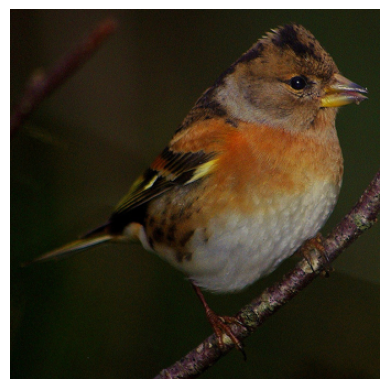

In [2]:
IMAGE_PATH = Path("/path/to/imagenet/val/n01530575/ILSVRC2012_val_00002730.JPEG")  # any RGB image
image = Image.open(IMAGE_PATH).convert("RGB")
# The model input geometry without normalisation, for display: [IMAGE_SIZE, IMAGE_SIZE] RGB.
crop = transforms.Compose([transforms.Resize(IMAGE_SIZE, interpolation=transforms.InterpolationMode.BICUBIC),
                           transforms.CenterCrop(IMAGE_SIZE)])(image)
plt.imshow(crop); plt.axis("off");

## Models and the region bank

Each model is a frozen backbone plus its linear probe. One seeded bank of keep masks is shared by every image and depth, so the depths are compared on identical draws.

21x21 patch tokens; 40.2 kept per draw (16-49)


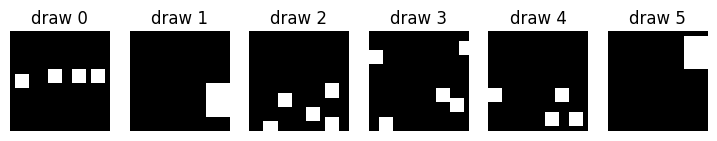

In [3]:
dinov3 = PrunableClassifier.from_probe(FrozenViT("dinov3_vitb16"), str(ROOT / "probes/dinov3_vitb16.safetensors"))
siglip2 = PrunableClassifier.from_probe(FrozenViT("siglip2_vitb16"), str(ROOT / "probes/siglip2_vitb16.safetensors"))
dinov3, siglip2 = dinov3.to(DEVICE).eval(), siglip2.to(DEVICE).eval()

bank = build_region_mask_bank(num_samples=NUM_DRAWS, num_tokens=NUM_PATCH_TOKENS,
                              num_keep=round(0.1 * NUM_PATCH_TOKENS), region_sizes=(3, 7), seed=42)  # [M, N]
kept = bank.sum(1).float()
print(f"{GRID_SIZE}x{GRID_SIZE} patch tokens; {kept.mean():.1f} kept per draw ({int(kept.min())}-{int(kept.max())})")
fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
for draw, ax in enumerate(axes):
    ax.imshow(bank[draw].reshape(GRID_SIZE, GRID_SIZE), cmap="gray"); ax.set_title(f"draw {draw}"); ax.axis("off")

## Token-impact maps

These are three settings. "Top-5 norm protected" keeps SigLIP 2's five highest-norm patch tokens entering block $l$ in every draw. SigLIP 2 has no [CLS] or register tokens, so pruning can otherwise remove its high-norm "sink" tokens. Protected tokens have no $\Delta$ (they are never dropped) and are marked with white dots.

In [4]:
settings = {
    "DINOv3 B/16": (dinov3, 0),
    "SigLIP 2 B/16": (siglip2, 0),
    "SigLIP 2 B/16, top-5 norm protected": (siglip2, 5),
}
results = {}
for name, (model, protect) in settings.items():
    pixels = image_transform(model.backbone.name)(image)[None].to(DEVICE)  # [1, 3, H, W]
    results[name] = token_impact_maps(model, pixels, depths=DEPTHS, bank=bank, protect_top_norm=protect)

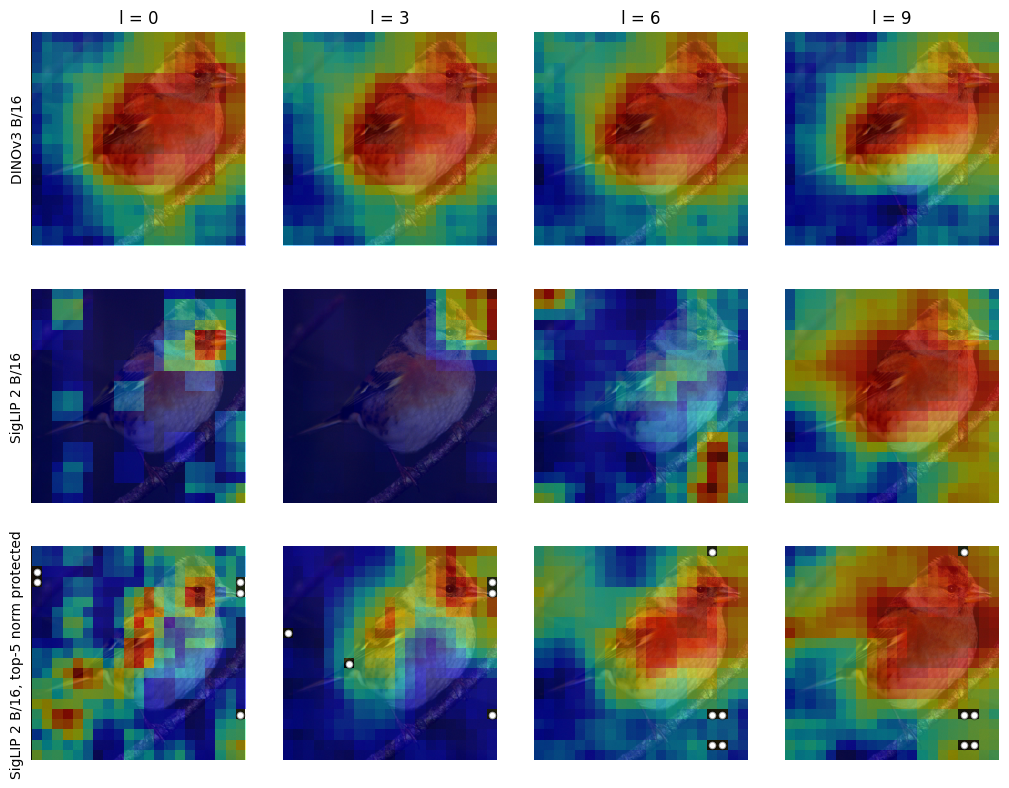

In [5]:
def show_map(ax, impacts, protected):
    # [N] -> [GRID, GRID]; each map is min-max scaled over its defined tokens; undefined tokens stay transparent.
    grid = impacts.reshape(GRID_SIZE, GRID_SIZE)
    scaled = (grid - np.nanmin(grid)) / (np.nanmax(grid) - np.nanmin(grid))
    ax.imshow(crop)
    ax.imshow(np.ma.masked_invalid(scaled), cmap="jet", alpha=0.5, extent=(0, IMAGE_SIZE, IMAGE_SIZE, 0),
              interpolation="nearest")
    rows, columns = np.nonzero(protected.reshape(GRID_SIZE, GRID_SIZE))
    patch = IMAGE_SIZE / GRID_SIZE
    ax.scatter((columns + 0.5) * patch, (rows + 0.5) * patch, s=30, c="white", edgecolors=(0, 0, 0, 0.35), linewidths=1.5)
    ax.axis("off")


fig, axes = plt.subplots(len(results), len(DEPTHS), figsize=(2.6 * len(DEPTHS), 2.7 * len(results)), squeeze=False)
for row, (name, maps) in enumerate(results.items()):
    for column, depth in enumerate(DEPTHS):
        show_map(axes[row, column], maps.impacts[0, column].numpy(), maps.protected[0, column].numpy())
        axes[row, column].set_title(f"l = {depth}" if row == 0 else "")
    axes[row, 0].text(-12, IMAGE_SIZE / 2, name, rotation=90, ha="right", va="center")
plt.tight_layout()

## Per-image summaries

- **Stability:** the share of draws whose top-1 is still $\hat y$.
- **Cross-depth agreement:** the Spearman correlation and the top-10% overlap of $\Delta$ between every pair of depths, averaged over pairs.
- **Effective support $\varphi^+$:** how widely the positive impact is spread. It is 1 for uniform impact and $1/N$ when the impact sits on one token.

In [6]:
class_names = ImageNetInfo()
pairs = list(combinations(range(len(DEPTHS)), 2))
summary = {}
for name, maps in results.items():
    impacts = maps.impacts[0].numpy()  # [D, N]
    stability = (maps.predictions[0] == maps.targets[0]).float().mean(-1).tolist()  # [D, M] -> [D]
    spearman = np.mean([spearman_correlation(impacts[a], impacts[b]) for a, b in pairs])
    overlap = np.mean([top_fraction_overlap(impacts[a], impacts[b], 0.1) for a, b in pairs])
    support = positive_effective_support(impacts)  # [D]
    summary[name] = {"stability": stability, "support": support.tolist()}
    print(f"{name}: predicts '{class_names.index_to_description(int(maps.targets[0]))}'")
    print(f"  stability by depth     {[round(value, 3) for value in stability]}")
    print(f"  effective support      {np.round(support, 3).tolist()}")
    print(f"  cross-depth Spearman   {spearman:.3f}   top-10% overlap {overlap:.3f}")

DINOv3 B/16: predicts 'brambling, Fringilla montifringilla'
  stability by depth     [0.768, 0.761, 0.834, 0.757]
  effective support      [0.431, 0.419, 0.413, 0.378]
  cross-depth Spearman   0.947   top-10% overlap 0.759
SigLIP 2 B/16: predicts 'brambling, Fringilla montifringilla'
  stability by depth     [0.01, 0.012, 0.141, 0.843]
  effective support      [0.241, 0.097, 0.252, 0.456]
  cross-depth Spearman   0.257   top-10% overlap 0.152
SigLIP 2 B/16, top-5 norm protected: predicts 'brambling, Fringilla montifringilla'
  stability by depth     [0.024, 0.211, 0.642, 0.851]
  effective support      [0.307, 0.301, 0.352, 0.458]
  cross-depth Spearman   0.428   top-10% overlap 0.292


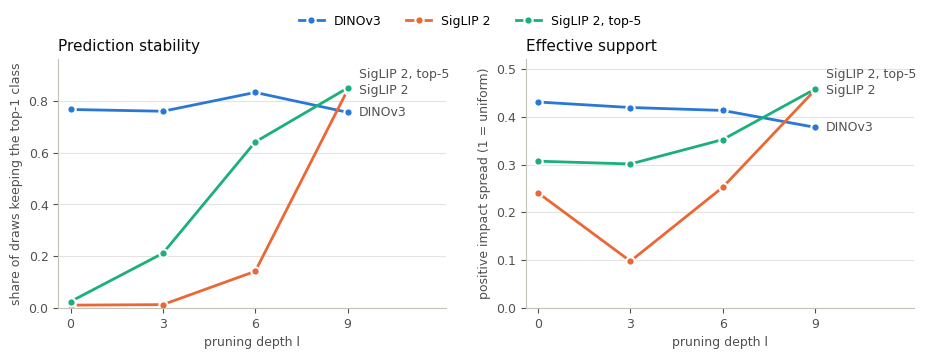

In [7]:
# One colour per setting, in a fixed order; lines are labelled directly and in the legend.
COLORS = {"DINOv3 B/16": "#2a78d6", "SigLIP 2 B/16": "#eb6834", "SigLIP 2 B/16, top-5 norm protected": "#1baf7a"}
SHORT = {"DINOv3 B/16": "DINOv3", "SigLIP 2 B/16": "SigLIP 2", "SigLIP 2 B/16, top-5 norm protected": "SigLIP 2, top-5"}
panels = [("stability", "Prediction stability", "share of draws keeping the top-1 class"),
          ("support", "Effective support", "positive impact spread (1 = uniform)")]

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, (key, title, ylabel) in zip(axes, panels):
    ends = []
    for name, values in summary.items():
        ax.plot(DEPTHS, values[key], color=COLORS[name], linewidth=2, marker="o", markersize=6,
                markeredgecolor="white", markeredgewidth=1.5, label=SHORT[name])
        ends.append([values[key][-1], SHORT[name]])
    # Direct labels at the line ends, nudged apart so close values do not collide.
    ends.sort()
    gap = 0.07 * max(value for value, _ in ends)
    for index in range(1, len(ends)):
        ends[index][0] = max(ends[index][0], ends[index - 1][0] + gap)
    for value, label in ends:
        ax.annotate(label, (DEPTHS[-1], value), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9, color="#52514e", annotation_clip=False)
    ax.set_ylim(0, max(ax.get_ylim()[1], ends[-1][0] + gap))
    ax.set_title(title, loc="left", fontsize=11, color="#0b0b0b")
    ax.set_ylabel(ylabel, fontsize=9, color="#52514e")
    ax.set_xlabel("pruning depth l", fontsize=9, color="#52514e")
    ax.set_xticks(DEPTHS)
    ax.set_xlim(DEPTHS[0] - 0.4, DEPTHS[-1] + 3.2)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.tick_params(colors="#52514e", labelsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False, fontsize=9,
           bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()

## Off-box mass (ImageNet validation images only)

Off-box mass is the share of positive impact that falls outside the ground-truth boxes, normalised by the area outside them. Uniform impact scores 1; impact entirely on the object scores 0. It is defined only when the unpruned prediction is the labelled class. Set `BOXES` to the official `ILSVRC2012_bbox_val_v3.tgz` (or its extracted XML directory) to compute it.

In [8]:
BOXES = Path("/path/to/ILSVRC2012_bbox_val_v3.tgz")  # None skips this section
if BOXES is not None:
    wnid = IMAGE_PATH.parent.name  # class folder in the standard val/<wnid>/ layout
    inside, visible_boxes = token_box_union(load_validation_boxes(Path(BOXES))[IMAGE_PATH.name], wnid)
    for name, maps in results.items():
        if class_names.index_to_label_name(int(maps.targets[0])) != wnid or not visible_boxes:
            print(f"{name}: not the labelled class, so off-box mass is undefined")
            continue
        masses = [normalised_off_box_mass(maps.impacts[0, d].numpy(), inside) for d in range(len(DEPTHS))]
        print(f"{name}: off-box mass by depth {[None if m is None else round(m, 3) for m in masses]}")

DINOv3 B/16: off-box mass by depth [0.18, 0.166, 0.198, 0.133]
SigLIP 2 B/16: off-box mass by depth [0.547, 1.954, 2.167, 0.208]
SigLIP 2 B/16, top-5 norm protected: off-box mass by depth [0.516, 0.924, 0.157, 0.341]
